In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

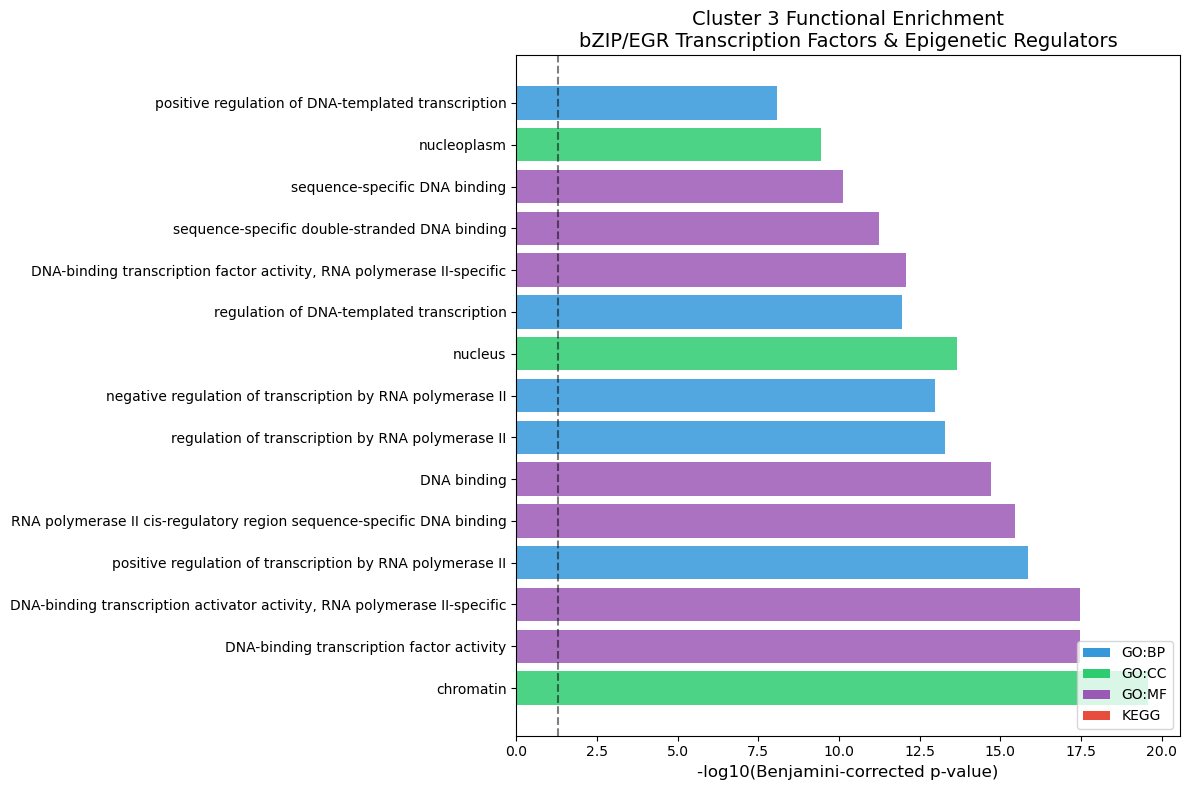


Records after category filter: 132
Category
GOTERM_BP_DIRECT    62
GOTERM_MF_DIRECT    33
KEGG_PATHWAY        28
GOTERM_CC_DIRECT     9
Name: count, dtype: int64

Top 15 terms:
            Category                                                                      Term  Count     Benjamini  Fold Enrichment
12  GOTERM_CC_DIRECT                                                                 chromatin     27  2.580000e-20            11.02
18  GOTERM_MF_DIRECT                                 DNA-binding transcription factor activity     23  3.500000e-18            13.63
23  GOTERM_MF_DIRECT  DNA-binding transcription activator activity, RNA polymerase II-specific     20  3.500000e-18            19.21
15  GOTERM_BP_DIRECT                 positive regulation of transcription by RNA polymerase II     26  1.360000e-16             9.28
17  GOTERM_MF_DIRECT     RNA polymerase II cis-regulatory region sequence-specific DNA binding     24  3.500000e-16             9.56
5   GOTERM_MF_DIRECT    

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cluster3_enrich = pd.read_csv('./results/enrichment/cluster3_enrichment.csv')

categories_keep = ['GOTERM_BP_DIRECT', 'GOTERM_CC_DIRECT', 
                   'GOTERM_MF_DIRECT', 'KEGG_PATHWAY']
filtered = cluster3_enrich[cluster3_enrich['Category'].isin(categories_keep)]
filtered = filtered.sort_values('P-Value').head(15)
filtered['-log10(FDR)'] = -np.log10(filtered['Benjamini'])

color_dict = {
    'GOTERM_BP_DIRECT': '#3498db',
    'GOTERM_CC_DIRECT': '#2ecc71',
    'GOTERM_MF_DIRECT': '#9b59b6',
    'KEGG_PATHWAY': '#e74c3c'
}
colors = [color_dict[cat] for cat in filtered['Category']]

plt.figure(figsize=(12, 8))
plt.barh(filtered['Term'], filtered['-log10(FDR)'], color=colors, alpha=0.85)
plt.xlabel('-log10(Benjamini-corrected p-value)', fontsize=12)
plt.title('Cluster 3 Functional Enrichment\nbZIP/EGR Transcription Factors & Epigenetic Regulators', fontsize=14)
plt.axvline(x=-np.log10(0.05), color='black', linestyle='--', alpha=0.5)

legend_elements = [Patch(facecolor='#3498db', label='GO:BP'),
                   Patch(facecolor='#2ecc71', label='GO:CC'),
                   Patch(facecolor='#9b59b6', label='GO:MF'),
                   Patch(facecolor='#e74c3c', label='KEGG')]
plt.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig('./figures/cluster3_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nRecords after category filter: {len(cluster3_enrich[cluster3_enrich['Category'].isin(categories_keep)])}")
print(cluster3_enrich[cluster3_enrich['Category'].isin(categories_keep)]['Category'].value_counts())
print("\nTop 15 terms:")
print(filtered[['Category', 'Term', 'Count', 'Benjamini', 'Fold Enrichment']].to_string())